In [17]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


# Data Preparation

In [6]:
df = pd.read_csv("a_cmi_internet.csv")
#legenda = pd.read_csv("data_dictionary.csv")

# Stagioni enceoded winter=0, spring=1, summer=2, autumn=3

df['Fitness_Endurance-Tempo_totale'] = df['Fitness_Endurance-Time_Sec'] + \
    (df['Fitness_Endurance-Time_Mins']*60)

In [7]:
# Colonne just to check
col_categoriche = df.select_dtypes(include=["object"]).columns
col_numeriche = df.select_dtypes(
    include=["int64", "float64"]).columns
col_quantitative = df.select_dtypes(
    include=["int64", "float64"]).columns.drop("id")

col_da_escludere = [
    "FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
    "FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
    "FGC-FGC_TL_Zone"
]

col_non_bin = col_quantitative.difference(col_da_escludere)

categoriche = df[col_categoriche]
stagioni = {"Winter": 0, "Spring": 1, "Summer": 2, "Fall": 3}
tutto_numerico = df.copy()
tutto_numerico[col_categoriche] = tutto_numerico[col_categoriche].replace(
    stagioni)
correlazione = tutto_numerico.corr()

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_6680/1928229715.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  tutto_numerico[col_categoriche] = tutto_numerico[col_categoriche].replace(


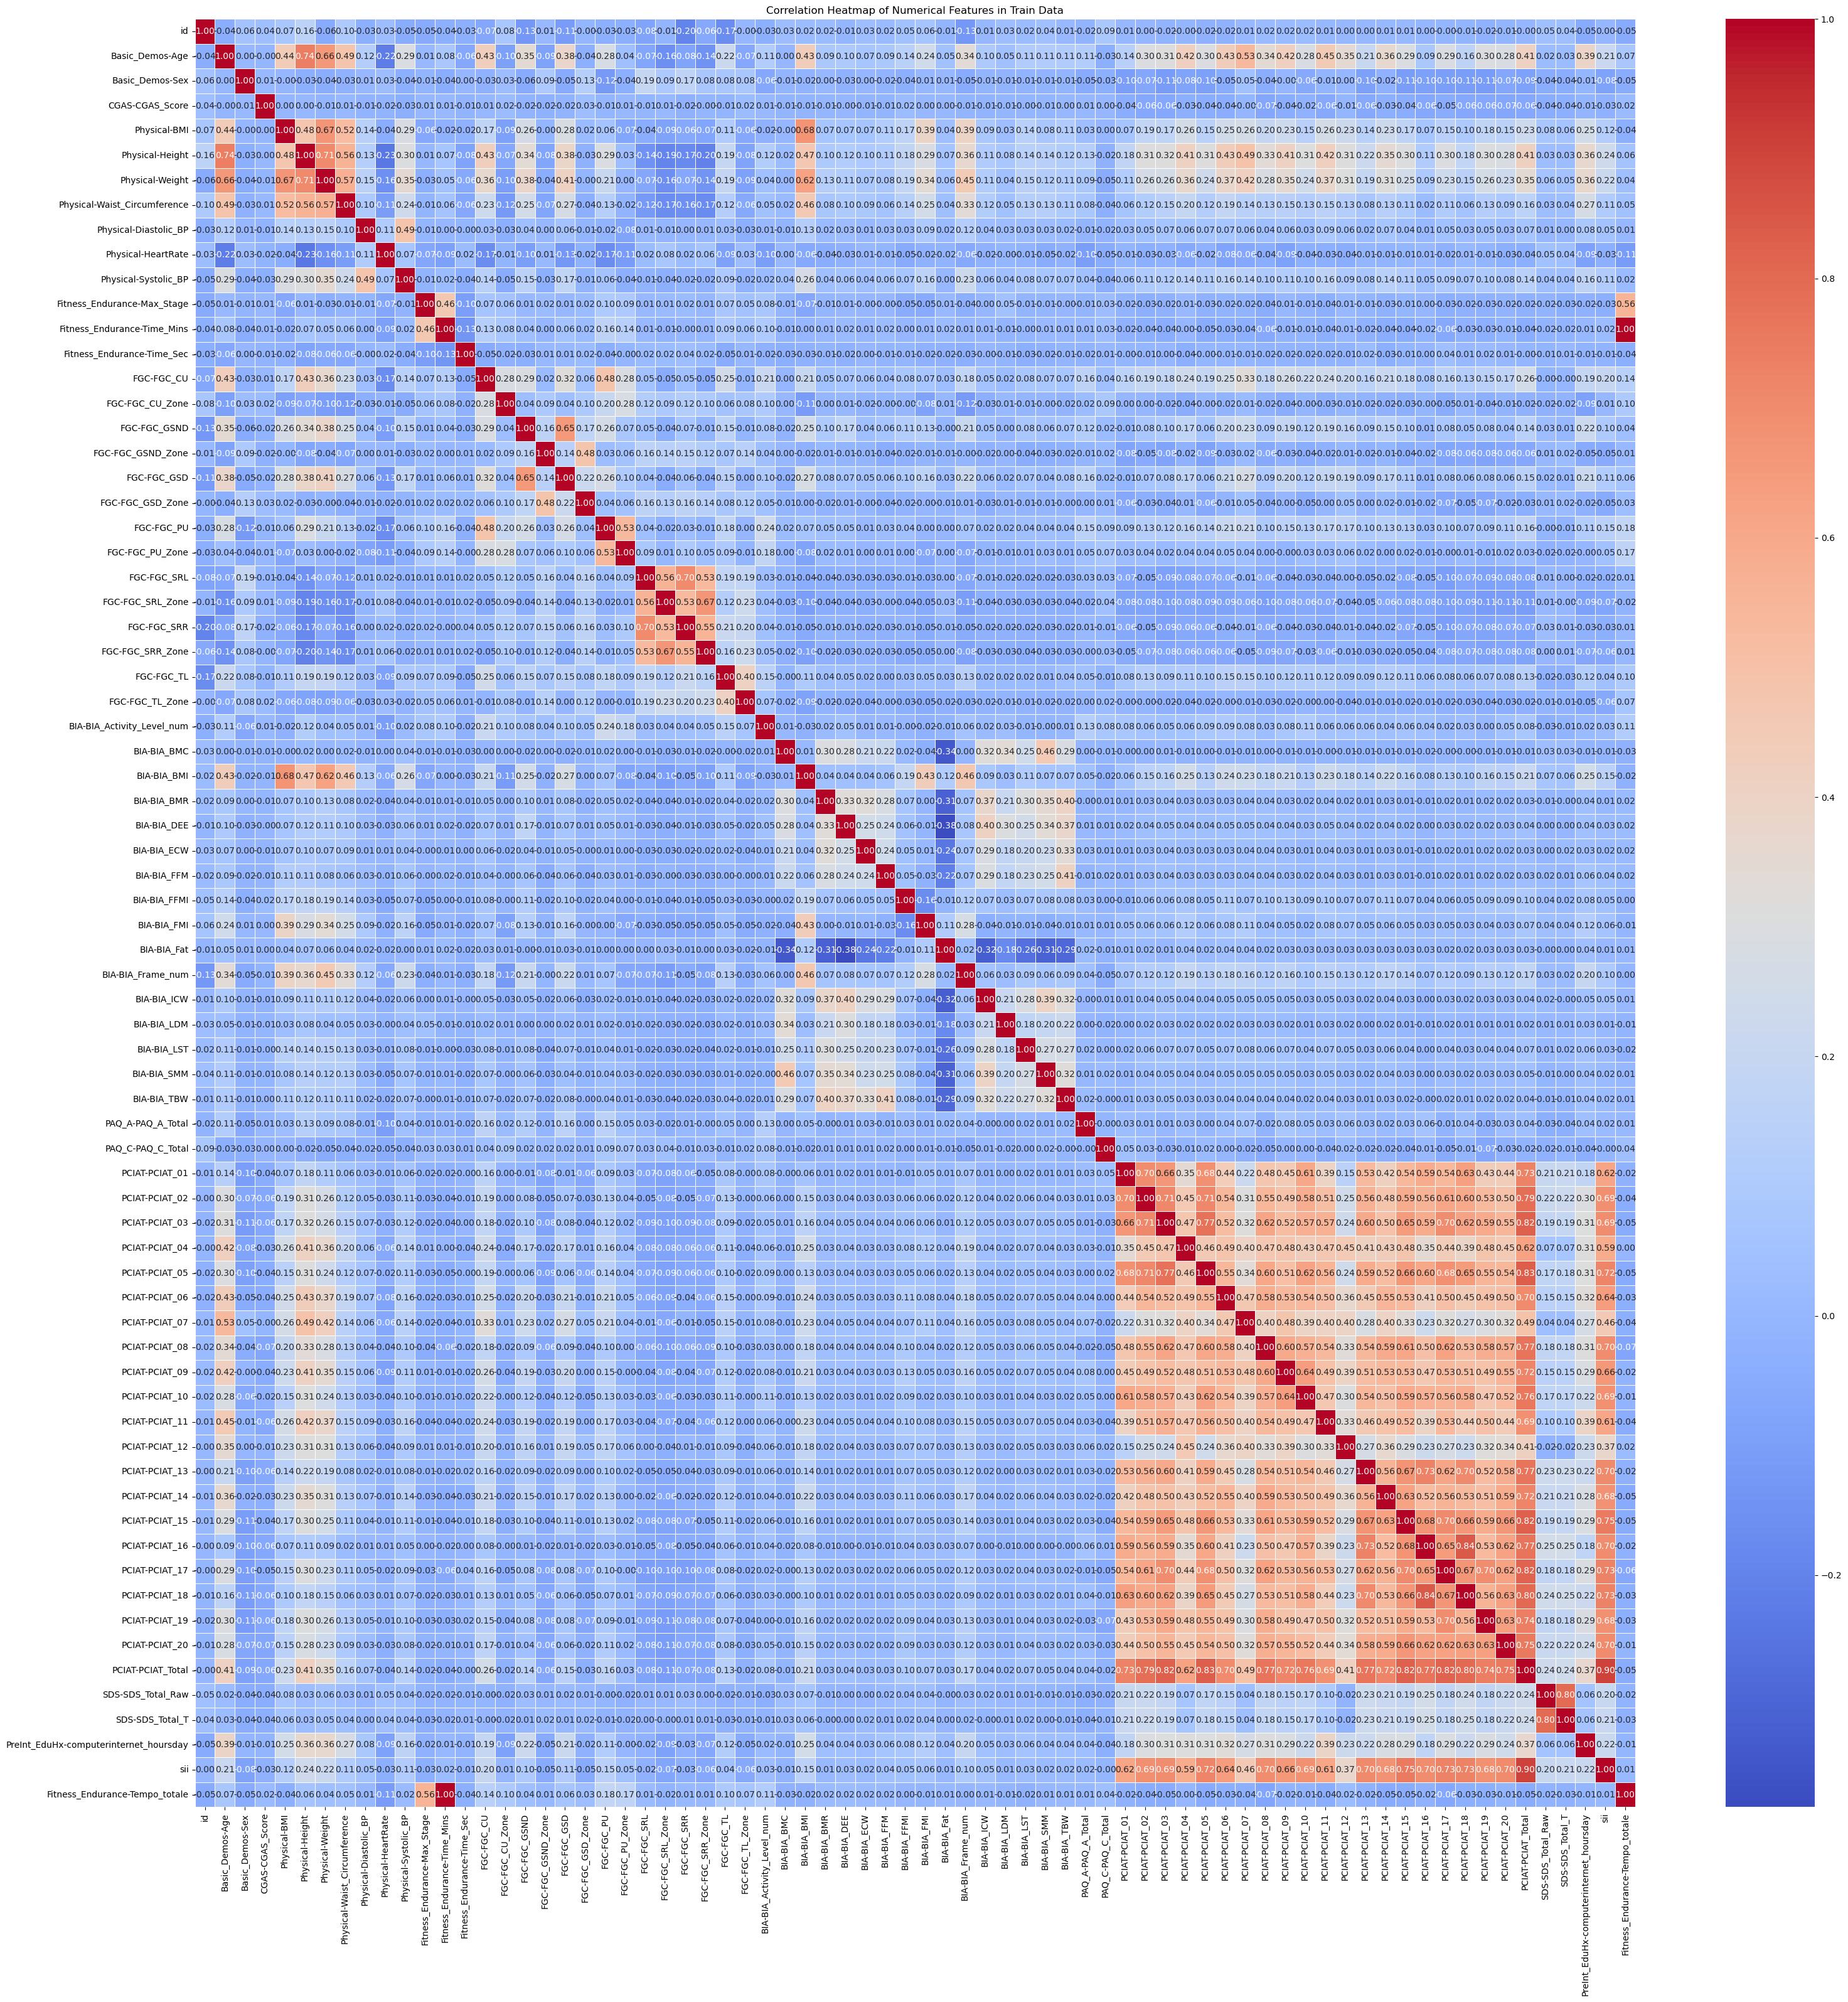

In [8]:
'''sns.set_theme(style="white")


def plot_professional_matrix(corr_matrix, title="Correlation Matrix"):
    # Creazione di una singola figura
    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

    # Maschera per nascondere la parte superiore (triangolo)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Palette divergente professionale (es. Rosso-Blu)
    cmap = sns.diverging_palette(230, 20, as_cmap=True)

    # Generazione della heatmap
    sns.heatmap(corr_matrix,
                mask=mask,
                cmap=cmap,
                vmax=1, vmin=-1, center=0,
                square=True,
                linewidths=.5,
                cbar_kws={"shrink": .5},
                annot=False,             # Impostare a True per mostrare i numeri
                fmt=".2f",               # Formato arrotondamento decimali
                ax=ax)

    # Impostazione del titolo
    ax.set_title(title, fontsize=16, pad=20)

    plt.show()


plot_professional_matrix(correlazione)'''

# Select only numerical columns for correlation matrix
numerical_columns = df.select_dtypes(include=['float64', 'int64'])

# Compute the correlation matrix
corr = numerical_columns.corr()

# Heatmap of correlation matrix
plt.figure(figsize=(32, 32))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features in Train Data')
plt.tight_layout()
plt.show()

In [9]:
# Fuori Scala

# CGAS-CGAS_Score
df["CGAS-CGAS_Score"] = df["CGAS-CGAS_Score"].mask(lambda x: x > 100, np.nan)

# Physical BMI
df["FGC-FGC_GSD"].value_counts()

FGC-FGC_GSD
21.20    1450
18.75    1365
19.00     109
18.50      89
24.75      62
         ... 
12.10       1
38.80       1
6.50        1
32.20       1
53.75       1
Name: count, Length: 452, dtype: int64

In [10]:
# Rimuovere 18+
# 0 = nan da lista
# paq Da arrotondare

df = df[df["Basic_Demos-Age"] <= 18]

df['PAQ_A-PAQ_A_Total'] = df['PAQ_A-PAQ_A_Total'].clip(lower=1)
df['PAQ_C-PAQ_C_Total'] = df['PAQ_C-PAQ_C_Total'].clip(lower=1)

colonne_zeri = ['Physical-BMI', 'Physical-Weight',
                'Physical-Diastolic_BP', 'Physical-Systolic_BP']
df[colonne_zeri] = df[colonne_zeri].mask(lambda x: x == 0, np.nan)


# train
train_set, test_set = train_test_split(
    df, test_size=0.3, stratify=df["sii"], random_state=222)

train_set = train_set.copy()
test_set = test_set.copy()

In [11]:
# imputazione

imputer = KNNImputer(n_neighbors=76)  # np.sqrt(5823)
train_imputed = pd.DataFrame(
    imputer.fit_transform(train_set[col_non_bin]),
    columns=col_non_bin,
    index=train_set.index)

test_imputed = pd.DataFrame(
    imputer.transform(test_set[col_non_bin]),
    columns=col_non_bin,
    index=test_set.index)

In [ ]:
# Salvataggio dati in CSV

#train_imputed.to_csv("train_imputed.csv", index=True)
#test_imputed.to_csv("test_imputed.csv", index=True)

In [41]:
train = pd.read_csv("train_imputed.csv")
test = pd.read_csv("test_imputed.csv")
tt = np.concatenate([train, test], axis=0)
df_unito = pd.DataFrame(tt, columns=train.columns)

# Outliers Detection

In [55]:
# come conviene gestire le stagioni? trasformarle in 1234 non ha senso in questo caso
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

y=np.array(df_unito['sii'])
X=df_unito.drop(columns=['sii']).values
X_standard=standard_scaler.fit_transform(X)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(X_standard, y, test_size=0.3, random_state=0)

In [56]:
# Ensemble: FeaBag

feabag_model = FeatureBagging(
    base_estimator=LOF(),  # stimatore base, si può cambiare
    n_estimators=100,  # da testare coi dati veri per capire quanto ci vuole
    max_features=0.5,  # proporzione di variabili da estrarre per ogni modello
    contamination=0.01,  # come prima, 1% di outliers
    random_state=222
)
feabag_model.fit(X_standard)

feabag_preds = feabag_model.predict(X_standard)

In [57]:
#Foreste: Extended Forest

# In isotree, ndim=1 equivale a Isolation Forest standard.
# Scegliere ndim=df.shape[1] per la Extended Isolation Forest completa.
extended_forest_model = EIF(
    sample_size=256,  # come prima
    ntrees=100,  # numero alberi
    # serve a dire al modello che vogliamo la versione estesa
    ndim=X_standard.shape[1],
    random_seed=222
)
extended_forest_model.fit(X_standard)

# EIF genera uno score (più alto = più probabile outlier)
extended_forest_scores = extended_forest_model.predict(X_standard)

# gli outlier vanno trovati a mano
threshold = np.percentile(extended_forest_scores, 99)  # 99 percentile
extended_forest_preds = (extended_forest_scores > threshold).astype(int)

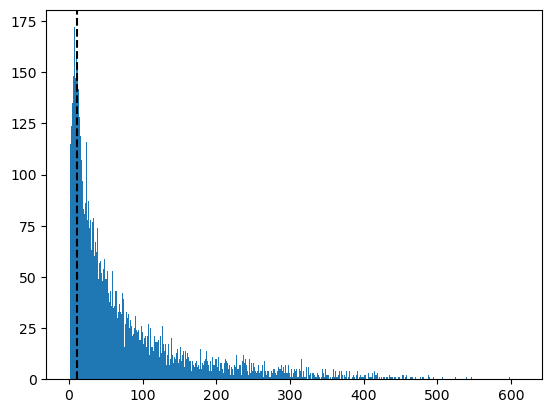

Numero di outlier trovati: 102 (1.23%)


In [58]:
#Distanza: RKNN
# 1. Trova i k-vicini per ogni punto
k = 76
nbrs = NearestNeighbors(n_neighbors=k).fit(X_standard)
distances, indices = nbrs.kneighbors(X_standard)

# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_standard))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out= np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')
plt.show()

n_outliers_rknn = np.sum(outliers_rknn)
print(f"Numero di outlier trovati: {int(n_outliers_rknn)} ({n_outliers_rknn/len(df_unito)*100:.2f}%)")



In [59]:
#Deviation-based Approaches: EllEnv

from sklearn.covariance import EllipticEnvelope

ellenv = EllipticEnvelope(random_state=222, contamination=0.01)
ellenv.fit(X_standard)

# predict returns 1 for an inlier and -1 for an outlier
outliers_ellenv = ellenv.predict(X_standard)

#print (outliers_ellenv)
np.unique(outliers_ellenv, return_counts=True)

n_outliers_ellenv = np.sum(outliers_ellenv == -1)
print(f"Numero di outlier trovati: {int(n_outliers_ellenv)} ({n_outliers_ellenv/len(df_unito)*100:.2f}%)")

Numero di outlier trovati: 84 (1.01%)


In [60]:

# High Dimensionality: Fast ABOD

#!!! LENTO, su portatile in carica ci mette 5+ minuti; sul fisso un paio

# Contamination è la proporzione di outliers; n_neighbors autoesplicativo
abod_model = ABOD(contamination=0.01, n_neighbors=76)
abod_model.fit(X_standard)

# 0 = inliers e 1 = outliers
abod_preds = abod_model.predict(X_standard)
abod_scores = abod_model.decision_scores_


In [61]:
df_outliers = pd.DataFrame(
    np.column_stack((outliers_rknn, outliers_ellenv,
                    feabag_preds, extended_forest_preds,abod_preds)),
    columns=['rknn', 'ellenv', 'feabag', 'ext_forest', 'abod']
)

df_outliers['risultati'] = (
    (df_outliers['rknn'] == 1).astype(int) +
    (df_outliers['ellenv'] == -1).astype(int) +
    (df_outliers['feabag'] == 1).astype(int) +
    (df_outliers['ext_forest'] == 1).astype(int) +
    (df_outliers['abod']== 1).astype(int)
)

df_outliers_2= df_outliers[df_outliers['risultati']>=2]
df_outliers_1= df_outliers[df_outliers['risultati']>=1]
df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)


In [62]:
# rimossi gli outliers che erano outliers per più di due metodi
df_unito['risultati'] = df_outliers['risultati'].values
df_pulito = df_unito[df_unito['risultati'] <= 1].copy()

print(f"Righe originali: {len(df_unito)}")
print(f"Righe dopo il filtro: {len(df_pulito)}")

df_solo_out=df_unito[df_unito['risultati'] > 1].copy()

Righe originali: 8319
Righe dopo il filtro: 8236


In [63]:
df_outliers.to_csv('df_outliers.csv')
df_pulito.to_csv('df_pulito.csv')

In [64]:
#outliers non rimossi ma resi null

df_out_imp = df_unito.copy()
# Lista di tutte le colonne tranne 'risultati'
colonne_da_svuotare = [c for c in df_out_imp.columns if c != 'risultati']

# Applica il nullo solo a quelle
df_out_imp.loc[df_out_imp['risultati'] >= 1, colonne_da_svuotare] = np.nan

In [ ]:
'''# Decision Tree

tree_class = DecisionTreeClassifier(
    criterion='gini', splitter="best", max_depth=7, min_samples_leaf=50, min_samples_split=0.01)
tree_class.fit(x_train_tree, y_train_tree)
plt.figure(figsize=(20, 4), dpi=1000)
plot_tree(tree_class, feature_names=colonnette, filled=True)
plt.show()

tree_class = DecisionTreeClassifier(
    criterion='gini', splitter="best", max_depth=3, min_samples_leaf=50, min_samples_split=0.01)
tree_class.fit(x_train_tree, y_train_tree)
plt.figure(figsize=(20, 4), dpi=1000)
plot_tree(tree_class, feature_names=colonnette, filled=True)
plt.show()

y_test_pred_tree = tree_class.predict(x_test_tree)
y_prob_tree = tree_class.predict_proba(x_test_tree)

# Esportazione
tree = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred_tree
})

tree['Prob_Class_0'] = y_prob_tree[:, 0]
tree['Prob_Class_1'] = y_prob_tree[:, 1]
tree['Prob_Class_2'] = y_prob_tree[:, 2]

tree.to_csv('tree.csv', index=False)'''

NameError: name 'x_train_tree' is not defined

# Dimensionality Reduction


In [70]:
%%time
#PCA
pca = PCA(n_components=3, random_state=222)
df_unito_pca = pca.fit_transform(X_standard)
print(pca.explained_variance_ratio_.sum()) 

0.3393716202127691
CPU times: user 2.72 ms, sys: 4.48 ms, total: 7.21 ms
Wall time: 5.26 ms


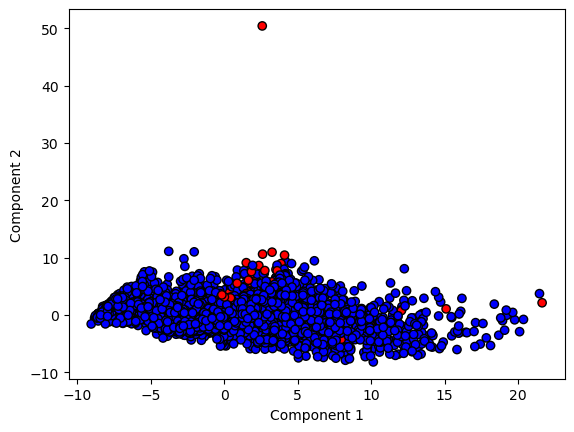

In [67]:
# 2D
fig, ax= plt.subplots()
plt.scatter(df_unito_pca[:, 0], df_unito_pca[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

import plotly.express as px

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_pca[:, 0],
    'Component 2': df_unito_pca[:, 1],
    'Component 3': df_unito_pca[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Viridis', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()



In [68]:
%%time
import umap
#UMAP
umappe = umap.UMAP(n_components = 3, random_state = 222)
df_unito_umap = umappe.fit_transform(X_standard)

CPU times: user 9.18 s, sys: 1.47 s, total: 10.7 s
Wall time: 7.78 s


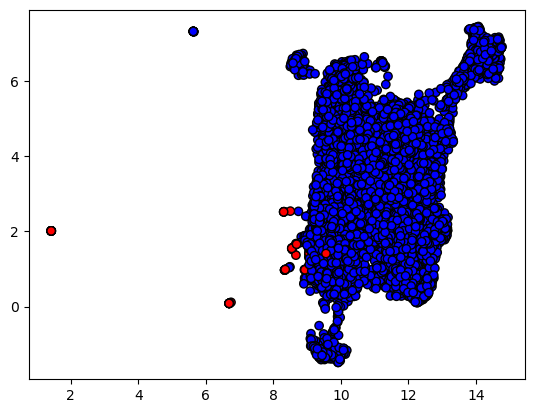

In [69]:
# 2D

plt.scatter(df_unito_umap[:, 0], df_unito_umap[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

#ax.set_xlabel('Component 1')
#ax.set_ylabel('Component 2')

plt.show()
import plotly.express as px
import pandas as pd

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_umap[:, 0],
    'Component 2': df_unito_umap[:, 1],
    'Component 3': df_unito_umap[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Plasma', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()


# Unbalanced Learning

In [71]:
import warnings
warnings.simplefilter("ignore")

In [ ]:
df_pulito= pd.read_csv('df_pulito.csv')

#nel df di guidotti a quanto pare la y si esclude in automatico per quello non la toglie lui. da correggere tutto quindi (fatto)

X_pulito = df_pulito.drop(columns=['sii']).values
y_pulito= np.array(df_pulito['sii'])

X_trainp, X_testp, y_trainp, y_testp = train_test_split(X_pulito, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

In [ ]:
## PCA
#pca = PCA(n_components=2)
#0.9509667633307275

pca = PCA(n_components=3)
#0.994901682495339

pca.fit(X_trainp)
X_pca = pca.transform(X_trainp)
print(X_trainp.shape, X_pca.shape)
print(pca.explained_variance_ratio_.sum()) 

(5765, 66) (5765, 2)
0.9509667633307275


In [74]:
cnn = CondensedNearestNeighbour(random_state=42, n_jobs=10)
X_res, y_res = cnn.fit_resample(X_train, y_train)
print('Resampled dataset shape %s' % Counter(y_res))

NameError: name 'CondensedNearestNeighbour' is not defined

In [ ]:
ada = ADASYN(random_state=42)
X_res, y_res = ada.fit_resample(X, y)
print('Resampled dataset shape %s' % Counter(y_res))